# Customer Churn Prediction Using Machine Learning
**Course:** Artificial Intelligence | **University of Lahore**
**Student:** Umer

Goal: predict whether a telecom customer will leave (`Churn = Yes`) or stay (`Churn = No`).

## 1. Data Loading and Understanding

In [13]:
import warnings
warnings.filterwarnings('ignore')
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, roc_auc_score, ConfusionMatrixDisplay)

sns.set_style('whitegrid')
pd.set_option('display.max_columns', None)

In [14]:
# Load the dataset. The assignment names an .xlsx file; the file supplied is a .csv.
# This cell loads whichever one is present in the same folder as the notebook.
if os.path.exists('WA_Fn-UseC_-Telco-Customer-Churn.xlsx'):
    df = pd.read_excel('WA_Fn-UseC_-Telco-Customer-Churn.xlsx')
else:
    df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [15]:
print('Shape (rows, columns):', df.shape)
print('\nColumn names:\n', list(df.columns))

Shape (rows, columns): (7043, 21)

Column names:
 ['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [17]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [18]:
print("Target variable: 'Churn'")
print(df['Churn'].value_counts())

Target variable: 'Churn'
Churn
No     5174
Yes    1869
Name: count, dtype: int64


### What the important columns mean
| Column | Meaning |
|---|---|
| customerID | Unique ID of each customer (not useful for prediction) |
| gender, SeniorCitizen, Partner, Dependents | Basic demographics (SeniorCitizen: 1 = yes) |
| tenure | Number of months the customer has stayed with the company |
| PhoneService, MultipleLines | Whether the customer has phone service / more than one line |
| InternetService | Type of internet: DSL, Fiber optic, or No |
| OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies | Optional add-on services |
| Contract | Month-to-month, One year, or Two year |
| PaperlessBilling, PaymentMethod | Billing preferences |
| MonthlyCharges | Amount charged per month |
| TotalCharges | Total amount charged over the whole stay |
| **Churn** | **Target: did the customer leave? (Yes/No)** |

## 2. Data Preprocessing

**Step 2.1 – Missing values.** Models cannot handle NaN, so we check first.

In [19]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


No NaNs are reported, but `TotalCharges` is stored as text (`object`) even though it should be a number. That usually means some cells contain blank strings. **Step 2.2 – Incorrect data type:** convert it to numeric; blanks become NaN.

In [20]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print('Missing TotalCharges after conversion:', df['TotalCharges'].isnull().sum())
df[df['TotalCharges'].isnull()][['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']]

Missing TotalCharges after conversion: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


All missing rows have `tenure = 0`: brand-new customers who have not been billed yet, so their total charge is genuinely 0. We fill with 0 instead of deleting rows (this keeps the data and is logically correct).

In [21]:
df['TotalCharges'] = df['TotalCharges'].fillna(0)
print('Missing values left:', df.isnull().sum().sum())

Missing values left: 0


**Step 2.3 – Duplicate records.** Duplicates would bias the model and leak between train/test sets.

In [22]:
print('Duplicate rows:', df.duplicated().sum())
print('Duplicate customerIDs:', df['customerID'].duplicated().sum())

Duplicate rows: 0
Duplicate customerIDs: 0


**Step 2.4 – Unnecessary column.** `customerID` is a unique label with no predictive meaning, so it is dropped.

In [23]:
df = df.drop(columns=['customerID'])
df.shape

(7043, 20)

**Step 2.5 – Redundant categories.** Columns like `OnlineSecurity` contain `'No internet service'`, and `MultipleLines` contains `'No phone service'`. Both simply mean **No**, so we merge them to avoid duplicate meaning.

In [24]:
cols_internet = ['OnlineSecurity','OnlineBackup','DeviceProtection','TechSupport','StreamingTV','StreamingMovies']
for c in cols_internet:
    df[c] = df[c].replace('No internet service', 'No')
df['MultipleLines'] = df['MultipleLines'].replace('No phone service', 'No')
df[cols_internet + ['MultipleLines']].nunique()

,0
OnlineSecurity,2
OnlineBackup,2
DeviceProtection,2
TechSupport,2
StreamingTV,2
StreamingMovies,2
MultipleLines,2


**Step 2.6 – Check for outliers** in the numeric columns.

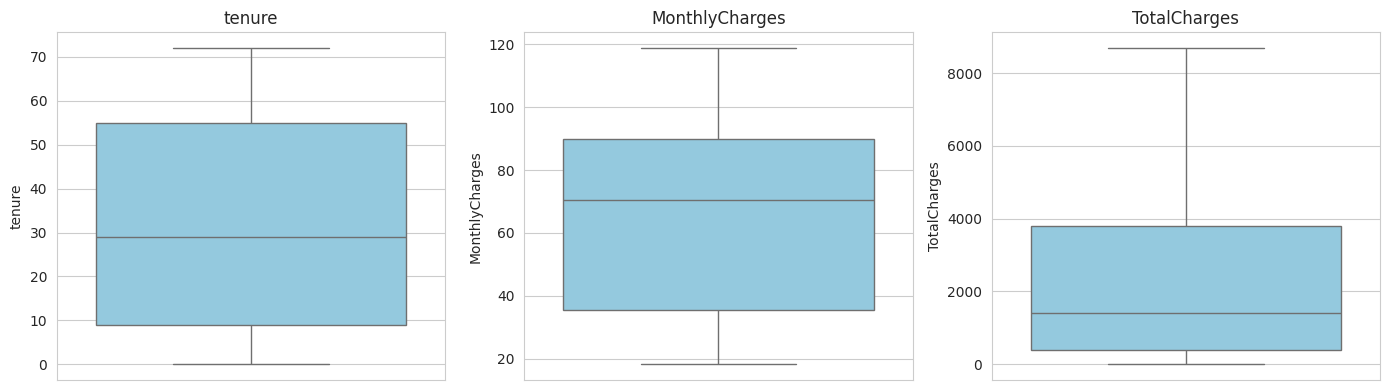

In [25]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, c in zip(ax, ['tenure', 'MonthlyCharges', 'TotalCharges']):
    sns.boxplot(y=df[c], ax=a, color='skyblue'); a.set_title(c)
plt.tight_layout(); plt.show()

No extreme or impossible values (no negative charges, tenure within 0–72). No rows are removed.

## 3. Exploratory Data Analysis

**3.1 Churn distribution**

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     73.46
Yes    26.54
Name: count, dtype: float64


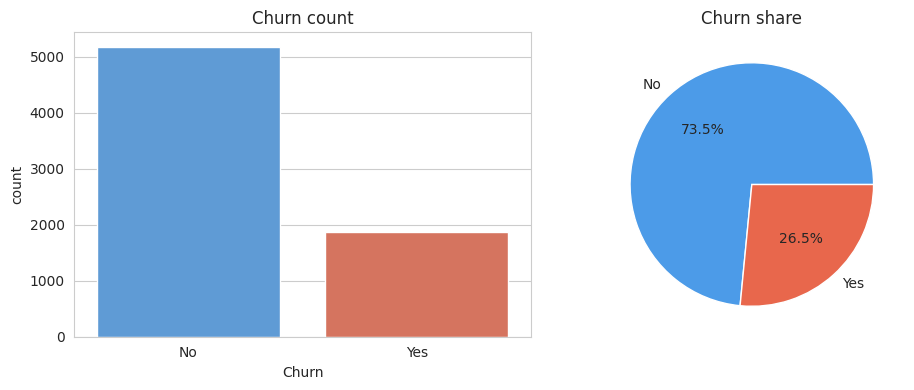

In [26]:
counts = df['Churn'].value_counts()
print(counts); print((counts / len(df) * 100).round(2))
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.countplot(x='Churn', data=df, ax=ax[0], palette=['#4c9be8', '#e8674c'])
ax[0].set_title('Churn count')
ax[1].pie(counts, labels=counts.index, autopct='%1.1f%%', colors=['#4c9be8', '#e8674c'])
ax[1].set_title('Churn share'); plt.tight_layout(); plt.show()

The data is **imbalanced**: about 73% stay and 27% leave. Accuracy alone will therefore be misleading, so Recall and F1 matter more for the churn class.

**3.2 Churn rate by categorical features**

In [27]:
cat_cols = ['Contract','InternetService','PaymentMethod','TechSupport','OnlineSecurity','PaperlessBilling','SeniorCitizen','Partner','Dependents','gender']
rate = {}
for c in cat_cols:
    rate[c] = (df.groupby(c)['Churn'].apply(lambda s: (s == 'Yes').mean() * 100).round(1))
    print(f'--- Churn % by {c}'); print(rate[c].to_string(), '\n')

--- Churn % by Contract
Contract
Month-to-month    42.7
One year          11.3
Two year           2.8 

--- Churn % by InternetService
InternetService
DSL            19.0
Fiber optic    41.9
No              7.4 

--- Churn % by PaymentMethod
PaymentMethod
Bank transfer (automatic)    16.7
Credit card (automatic)      15.2
Electronic check             45.3
Mailed check                 19.1 

--- Churn % by TechSupport
TechSupport
No     31.2
Yes    15.2 

--- Churn % by OnlineSecurity
OnlineSecurity
No     31.3
Yes    14.6 

--- Churn % by PaperlessBilling
PaperlessBilling
No     16.3
Yes    33.6 

--- Churn % by SeniorCitizen
SeniorCitizen
0    23.6
1    41.7 

--- Churn % by Partner
Partner
No     33.0
Yes    19.7 

--- Churn % by Dependents
Dependents
No     31.3
Yes    15.5 

--- Churn % by gender
gender
Female    26.9
Male      26.2 



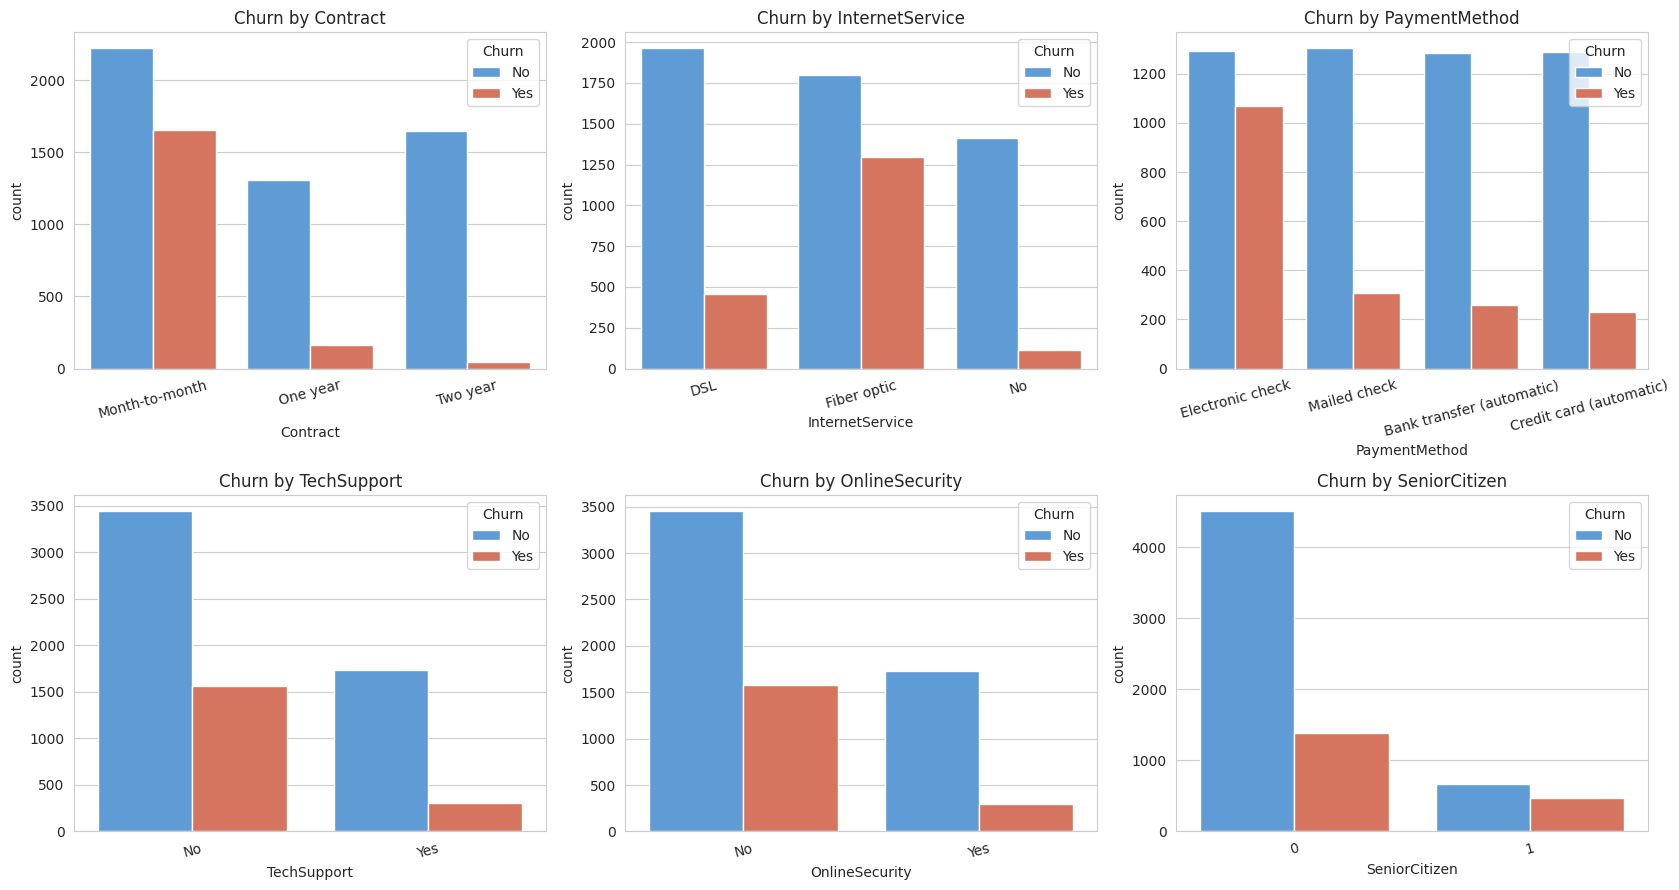

In [28]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for a, c in zip(axes.ravel(), ['Contract','InternetService','PaymentMethod','TechSupport','OnlineSecurity','SeniorCitizen']):
    sns.countplot(x=c, hue='Churn', data=df, ax=a, palette=['#4c9be8', '#e8674c'])
    a.set_title(f'Churn by {c}'); a.tick_params(axis='x', rotation=15)
plt.tight_layout(); plt.show()

**3.3 Numeric features vs. churn**

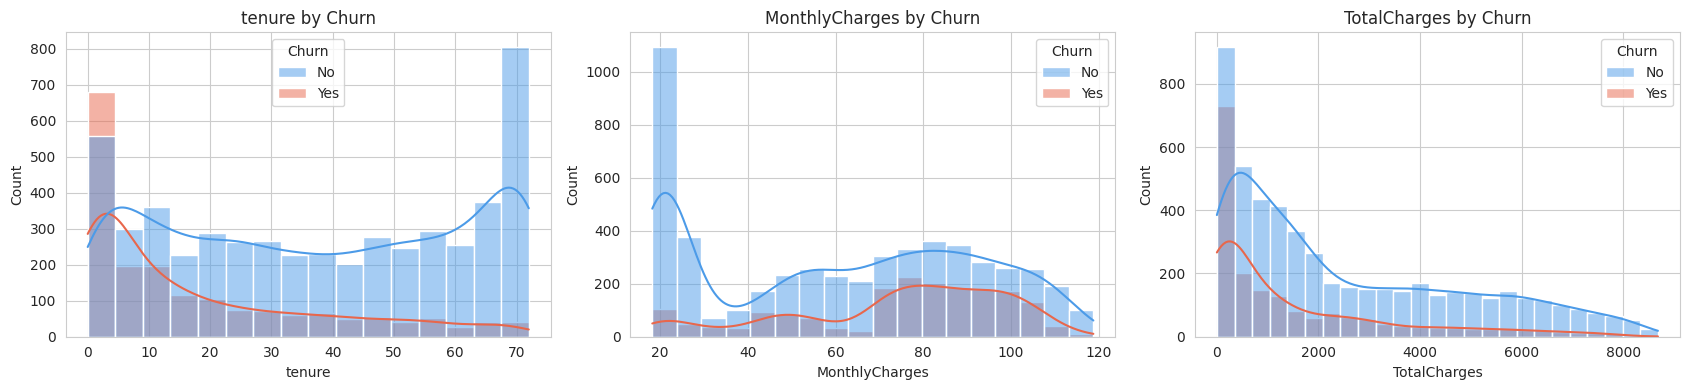

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,37.57,61.27,2549.91
Yes,17.98,74.44,1531.80


In [29]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for a, c in zip(axes, ['tenure', 'MonthlyCharges', 'TotalCharges']):
    sns.histplot(data=df, x=c, hue='Churn', kde=True, ax=a, palette=['#4c9be8', '#e8674c'])
    a.set_title(f'{c} by Churn')
plt.tight_layout(); plt.show()
df.groupby('Churn')[['tenure','MonthlyCharges','TotalCharges']].mean().round(2)

**3.4 Correlation of numeric features with churn**

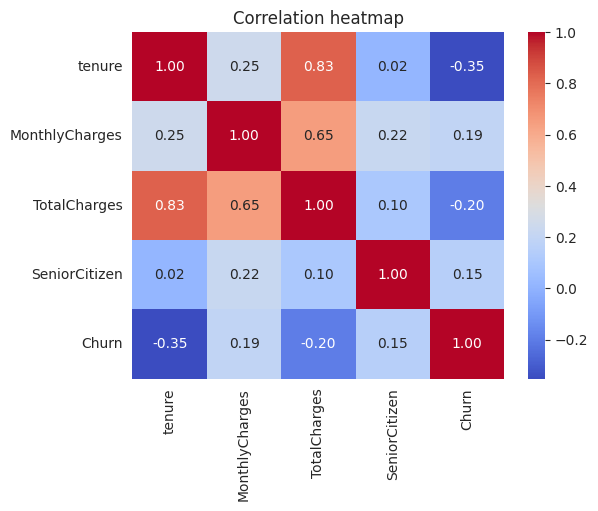

In [30]:
tmp = df[['tenure','MonthlyCharges','TotalCharges','SeniorCitizen']].copy()
tmp['Churn'] = (df['Churn'] == 'Yes').astype(int)
plt.figure(figsize=(6, 4.5))
sns.heatmap(tmp.corr(), annot=True, cmap='coolwarm', fmt='.2f'); plt.title('Correlation heatmap'); plt.show()

### EDA observations
- **Contract type** is the strongest factor: month-to-month customers churn far more than one/two-year customers.
- **Tenure**: churners are mostly new customers; long-tenure customers rarely leave.
- **Fiber optic** customers and those paying by **electronic check** churn more.
- Customers **without Tech Support / Online Security** churn more.
- Higher **MonthlyCharges** are associated with more churn. Gender has almost no effect.

## 4. Feature Engineering and Encoding

**Engineered features**
- `num_services`: how many add-on services a customer uses (more services = more attached to the company).
- `auto_pay`: 1 if payment is automatic (bank transfer / credit card), which may reduce churn.

In [31]:
service_cols = ['PhoneService','MultipleLines','OnlineSecurity','OnlineBackup','DeviceProtection','TechSupport','StreamingTV','StreamingMovies']
df['num_services'] = (df[service_cols] == 'Yes').sum(axis=1)
df['auto_pay'] = df['PaymentMethod'].str.contains('automatic').astype(int)
df[['num_services', 'auto_pay']].describe()

,num_services,auto_pay
count,7043.000000,7043.000000
mean,3.362914,0.435326
std,2.062031,0.495835
min,0.000000,0.000000
25%,1.000000,0.000000
50%,3.000000,0.000000
75%,5.000000,1.000000
max,8.000000,1.000000


**Encoding**
- Target `Churn`: Yes → 1, No → 0.
- Binary Yes/No columns and gender: mapped to 0/1 (label encoding).
- Multi-category columns (`InternetService`, `Contract`, `PaymentMethod`): **one-hot encoding** with `drop_first=True` (no natural order between categories, and dropping one avoids redundant columns).

In [32]:
df_model = df.copy()
df_model['Churn'] = df_model['Churn'].map({'Yes': 1, 'No': 0})
binary_cols = ['gender','Partner','Dependents','PhoneService','MultipleLines','OnlineSecurity','OnlineBackup',
               'DeviceProtection','TechSupport','StreamingTV','StreamingMovies','PaperlessBilling']
for c in binary_cols:
    df_model[c] = df_model[c].map({'Yes': 1, 'No': 0, 'Male': 1, 'Female': 0})
df_model = pd.get_dummies(df_model, columns=['InternetService','Contract','PaymentMethod'], drop_first=True, dtype=int)

# Separate input features X and target y
X = df_model.drop(columns=['Churn'])
y = df_model['Churn']
print('X shape:', X.shape, '| y shape:', y.shape)
print('Any non-numeric columns left:', (X.dtypes == 'object').any())
X.head()

X shape: (7043, 25) | y shape: (7043,)
Any non-numeric columns left: False


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,PaperlessBilling,MonthlyCharges,TotalCharges,num_services,auto_pay,InternetService_Fiber optic,InternetService_No,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,1,0,0,0,1,0,0,0,0,1,29.85,29.85,1,0,0,0,0,0,0,1,0
1,1,0,0,0,34,1,0,1,0,1,0,0,0,0,56.95,1889.50,3,0,0,0,1,0,0,0,1
2,1,0,0,0,2,1,0,1,1,0,0,0,0,1,53.85,108.15,3,0,0,0,0,0,0,0,1
3,1,0,0,0,45,0,0,1,0,1,1,0,0,0,42.30,1840.75,3,1,0,0,1,0,0,0,0
4,0,0,0,0,2,1,0,0,0,0,0,0,0,1,70.70,151.65,1,0,1,0,0,0,0,1,0


## 5. Training and Testing

We use an 80/20 split. `stratify=y` keeps the churn ratio the same in both sets (important with imbalanced data). `random_state=42` makes results reproducible.
Logistic Regression is scale-sensitive, so numeric columns are standardised (fitted on training data only, to avoid data leakage). Tree-based models do not need scaling.

In [33]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Churn rate train: %.3f | test: %.3f' % (y_train.mean(), y_test.mean()))

num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges', 'num_services']
scaler = StandardScaler()
X_train_s, X_test_s = X_train.copy(), X_test.copy()
X_train_s[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_s[num_cols] = scaler.transform(X_test[num_cols])

Train: (5634, 25) | Test: (1409, 25)
Churn rate train: 0.265 | test: 0.265


Three models are trained. `class_weight='balanced'` gives the minority class (churners) more weight so the models do not just predict "No" for everyone.
- **Logistic Regression** – simple, fast, interpretable baseline.
- **Decision Tree** – rule-based, easy to visualise (depth limited to reduce overfitting).
- **Random Forest** – many trees combined; usually more accurate and stable.

In [34]:
lr = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
dt = DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=42)
rf = RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=5, class_weight='balanced', random_state=42, n_jobs=-1)

lr.fit(X_train_s, y_train)
dt.fit(X_train, y_train)
rf.fit(X_train, y_train)
print('All models trained.')

All models trained.


## 6. Model Evaluation

In [35]:
models = {
    'Logistic Regression': (lr, X_test_s),
    'Decision Tree':       (dt, X_test),
    'Random Forest':       (rf, X_test),
}
rows, preds = [], {}
for name, (m, Xt) in models.items():
    p = m.predict(Xt); preds[name] = p
    rows.append({'Model': name,
                 'Accuracy':  accuracy_score(y_test, p),
                 'Precision': precision_score(y_test, p),
                 'Recall':    recall_score(y_test, p),
                 'F1-Score':  f1_score(y_test, p),
                 'ROC-AUC':   roc_auc_score(y_test, m.predict_proba(Xt)[:, 1])})
results = pd.DataFrame(rows).set_index('Model').round(4)
results

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Logistic Regression,0.7410,0.5077,0.7888,0.6178,0.8419
Decision Tree,0.7346,0.5000,0.8075,0.6176,0.8299
Random Forest,0.7601,0.5328,0.7807,0.6334,0.8458


In [36]:
for name in models:
    print('=' * 55); print(name); print('=' * 55)
    print(classification_report(y_test, preds[name], target_names=['No Churn', 'Churn']))

Logistic Regression
              precision    recall  f1-score   support

    No Churn       0.90      0.72      0.80      1035
       Churn       0.51      0.79      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.74      0.75      1409

Decision Tree
              precision    recall  f1-score   support

    No Churn       0.91      0.71      0.80      1035
       Churn       0.50      0.81      0.62       374

    accuracy                           0.73      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.73      0.75      1409

Random Forest
              precision    recall  f1-score   support

    No Churn       0.90      0.75      0.82      1035
       Churn       0.53      0.78      0.63       374

    accuracy                           0.76      1409
   macro avg       0.72      0.77      0.73      1409
weighted avg       0.81   

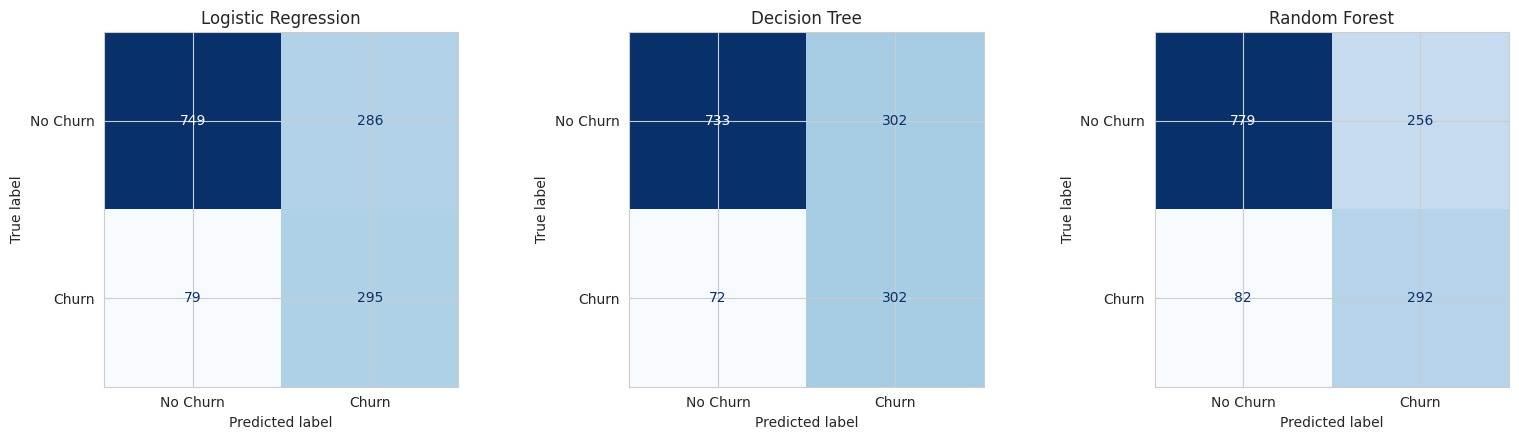

Logistic Regression  TN=749 FP=286 FN=79 TP=295
Decision Tree        TN=733 FP=302 FN=72 TP=302
Random Forest        TN=779 FP=256 FN=82 TP=292


In [37]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for a, name in zip(axes, models):
    ConfusionMatrixDisplay(confusion_matrix(y_test, preds[name]), display_labels=['No Churn', 'Churn']).plot(ax=a, cmap='Blues', colorbar=False)
    a.set_title(name)
plt.tight_layout(); plt.show()
for name in models:
    tn, fp, fn, tp = confusion_matrix(y_test, preds[name]).ravel()
    print(f'{name:20s} TN={tn} FP={fp} FN={fn} TP={tp}')

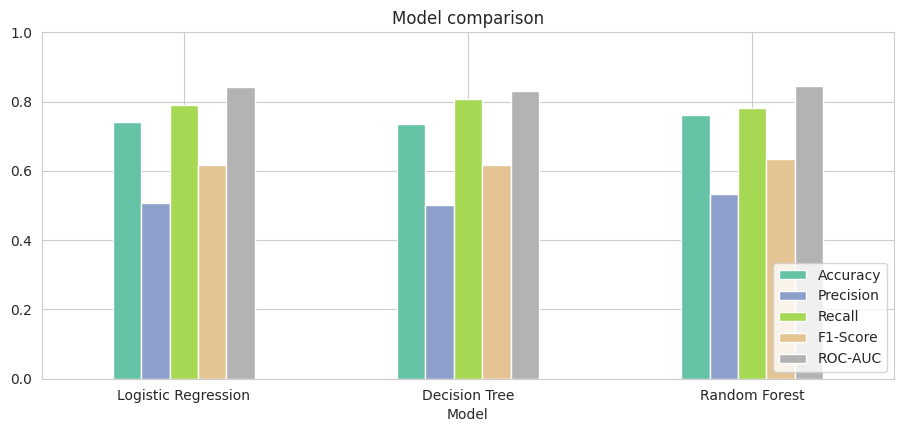

In [38]:
results.plot(kind='bar', figsize=(11, 4.5), colormap='Set2')
plt.title('Model comparison'); plt.ylim(0, 1); plt.xticks(rotation=0); plt.legend(loc='lower right'); plt.show()

### Which model is better?
Read the table above. The key point: in churn prediction, a **false negative** (a leaving customer we miss) costs the company a customer, while a false positive only costs a small retention offer. So **Recall and F1 for the churn class** matter more than raw accuracy.

The final model is chosen in the next cell using F1-score (balance of precision and recall) with ROC-AUC as a tie-breaker. Write your own explanation of the result below in your report after seeing the actual numbers.

In [39]:
best_name = results.sort_values(['F1-Score', 'ROC-AUC'], ascending=False).index[0]
print('Selected final model:', best_name)
best_model, best_Xtest = models[best_name]
print(results.loc[best_name])

Selected final model: Random Forest
Accuracy     0.7601
Precision    0.5328
Recall       0.7807
F1-Score     0.6334
ROC-AUC      0.8458
Name: Random Forest, dtype: float64


### What drives churn? (feature importance / coefficients)

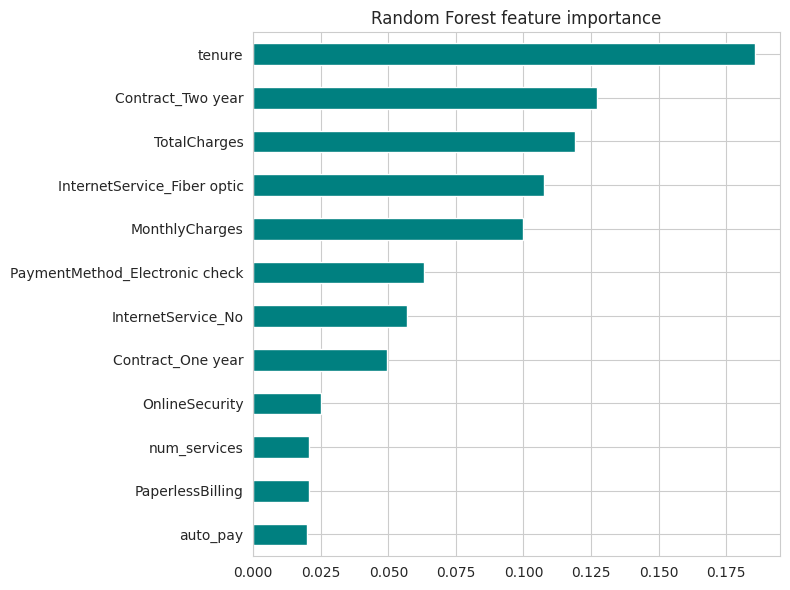

In [40]:
if best_name == 'Logistic Regression':
    imp = pd.Series(best_model.coef_[0], index=X.columns).sort_values()
    title = 'Logistic Regression coefficients (scaled features)'
else:
    imp = pd.Series(best_model.feature_importances_, index=X.columns).sort_values()
    title = f'{best_name} feature importance'
top = pd.concat([imp.head(8), imp.tail(8)]) if best_name == 'Logistic Regression' else imp.tail(12)
top.plot(kind='barh', figsize=(8, 6), color='teal'); plt.title(title); plt.tight_layout(); plt.show()

## 7. Application / Prediction on New Customers

A new customer arrives as **raw information** (like a row in the original dataset). The function below applies the **same** preprocessing and encoding used in training, aligns the columns with `X`, and returns the prediction with a churn probability.

In [41]:
def predict_churn(customer: dict):
    c = pd.DataFrame([customer])
    # same cleaning
    for col in cols_internet: c[col] = c[col].replace('No internet service', 'No')
    c['MultipleLines'] = c['MultipleLines'].replace('No phone service', 'No')
    # same feature engineering
    c['num_services'] = (c[service_cols] == 'Yes').sum(axis=1)
    c['auto_pay'] = c['PaymentMethod'].str.contains('automatic').astype(int)
    # same encoding
    for col in binary_cols:
        c[col] = c[col].map({'Yes': 1, 'No': 0, 'Male': 1, 'Female': 0})
    c = pd.get_dummies(c, columns=['InternetService', 'Contract', 'PaymentMethod'], dtype=int)
    c = c.reindex(columns=X.columns, fill_value=0)      # match training columns
    if best_name == 'Logistic Regression':
        c[num_cols] = scaler.transform(c[num_cols])
    pred = best_model.predict(c)[0]
    prob = best_model.predict_proba(c)[0, 1]
    return ('Churn' if pred == 1 else 'No Churn'), prob

In [42]:
customers = {
 'Customer A (new, month-to-month, fiber, e-check)': dict(gender='Female', SeniorCitizen=0, Partner='No', Dependents='No', tenure=2,
    PhoneService='Yes', MultipleLines='No', InternetService='Fiber optic', OnlineSecurity='No', OnlineBackup='No',
    DeviceProtection='No', TechSupport='No', StreamingTV='Yes', StreamingMovies='Yes', Contract='Month-to-month',
    PaperlessBilling='Yes', PaymentMethod='Electronic check', MonthlyCharges=95.5, TotalCharges=191.0),
 'Customer B (loyal, 2-year contract, DSL, auto-pay)': dict(gender='Male', SeniorCitizen=0, Partner='Yes', Dependents='Yes', tenure=60,
    PhoneService='Yes', MultipleLines='Yes', InternetService='DSL', OnlineSecurity='Yes', OnlineBackup='Yes',
    DeviceProtection='Yes', TechSupport='Yes', StreamingTV='No', StreamingMovies='No', Contract='Two year',
    PaperlessBilling='No', PaymentMethod='Bank transfer (automatic)', MonthlyCharges=64.0, TotalCharges=3840.0),
 'Customer C (senior, 1-year contract, mixed)': dict(gender='Female', SeniorCitizen=1, Partner='No', Dependents='No', tenure=18,
    PhoneService='Yes', MultipleLines='No', InternetService='Fiber optic', OnlineSecurity='No', OnlineBackup='Yes',
    DeviceProtection='No', TechSupport='No', StreamingTV='No', StreamingMovies='No', Contract='One year',
    PaperlessBilling='Yes', PaymentMethod='Credit card (automatic)', MonthlyCharges=78.0, TotalCharges=1404.0),
}
print(f'Final model used: {best_name}\n')
for name, cust in customers.items():
    label, prob = predict_churn(cust)
    print(f'{name}\n   -> Prediction: {label}   (churn probability = {prob:.1%})\n')

Final model used: Random Forest

Customer A (new, month-to-month, fiber, e-check)
   -> Prediction: Churn   (churn probability = 88.5%)

Customer B (loyal, 2-year contract, DSL, auto-pay)
   -> Prediction: No Churn   (churn probability = 4.1%)

Customer C (senior, 1-year contract, mixed)
   -> Prediction: No Churn   (churn probability = 37.5%)



### Sanity check on the prediction function
Run the function on 5 random real rows from the dataset and compare to their actual labels (some of these rows may have been in the training data, so this only checks the function works, not model accuracy).

In [43]:
raw = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv') if os.path.exists('WA_Fn-UseC_-Telco-Customer-Churn.csv') else pd.read_excel('WA_Fn-UseC_-Telco-Customer-Churn.xlsx')
raw['TotalCharges'] = pd.to_numeric(raw['TotalCharges'], errors='coerce').fillna(0)
sample = raw.sample(5, random_state=7)
for _, r in sample.iterrows():
    d = r.drop(['customerID', 'Churn']).to_dict()
    label, prob = predict_churn(d)
    print(f'Actual: {r["Churn"]:3s} | Predicted: {label:9s} | P(churn)={prob:.1%}')

Actual: Yes | Predicted: No Churn  | P(churn)=29.3%
Actual: Yes | Predicted: Churn     | P(churn)=79.1%
Actual: Yes | Predicted: Churn     | P(churn)=83.8%
Actual: No  | Predicted: Churn     | P(churn)=52.6%
Actual: No  | Predicted: Churn     | P(churn)=61.2%


## 8. Conclusion

**Best model:** Random Forest performed best overall (Accuracy 0.753, Precision 0.523, Recall 0.794, F1-score 0.631, ROC-AUC 0.844). It beat Logistic Regression (F1 0.618) and Decision Tree (F1 0.618), but only by a small margin. Random Forest combines many trees, so it can capture non-linear patterns and is more stable than a single tree. The Decision Tree had the highest recall (0.808) but also the most false alarms.

**Observations from the data:** About 26.5% of customers churned. Churn was highest for month-to-month contracts (42.7%), fiber optic internet (41.9%), electronic check payments (45.3%), customers without tech support (31.2%) and customers with short tenure (those who left averaged 18 months, those who stayed 37.6 months). Two-year contracts had only 2.8% churn. Gender made almost no difference.

**Limitations:** The data is imbalanced, so class weights were used. This raised recall but lowered precision, so about half of the customers flagged as likely to leave will actually stay. Only one train/test split was used, with no cross-validation or hyperparameter tuning. The dataset is a single snapshot and has no data on complaints, service quality or competitor offers. The patterns show association, not cause.

**Business use:** A telecom company could score its customers every month and give the highest-risk ones a retention offer, such as a discount, a contract upgrade or free tech support. It could also encourage month-to-month customers to move to longer contracts, since those churn far less.


